In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import subprocess
import sys

for package in ["seaborn", "lifelines"]:
    try:
        __import__(package)
    except ModuleNotFoundError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import seaborn as sns
from pathlib import Path
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

sns.set_theme(style="whitegrid")

cwd = Path.cwd()
PROJECT_DIR = cwd if (cwd / "dataset").exists() else cwd.parent
DATA_PATH = PROJECT_DIR / "dataset" / "heart_failure_cleaned.csv"
if not DATA_PATH.exists():
    alt_path = PROJECT_DIR / "dataset" / "heart_failure_clinical_records_dataset.csv"
    if alt_path.exists():
        DATA_PATH = alt_path

df = pd.read_csv("C:\\Users\\vaibh\\OneDrive\\Desktop\\Heart_Failure_Survival_Analysis\\dataset\\heart_failure_clinical_records_dataset.csv")
print("Dataset loaded:", df.shape)


Dataset loaded: (299, 13)


In [2]:

# Duration is follow-up time in days
# Event is 1 if death occurred, 0 if right-censored
survival_df = df[["time", "DEATH_EVENT"]].copy()

survival_df = survival_df.rename(columns={
    "time": "duration",
    "DEATH_EVENT": "event"
})

survival_df["event"] = survival_df["event"].astype(int)

print("Total patients:", len(survival_df))
print("Recorded deaths:", survival_df["event"].sum())
print("Censored observations:", (survival_df["event"] == 0).sum())

display(survival_df.head())


Total patients: 299
Recorded deaths: 96
Censored observations: 203


,duration,event
0,4,1
1,6,1
2,7,1
3,7,1
4,8,1


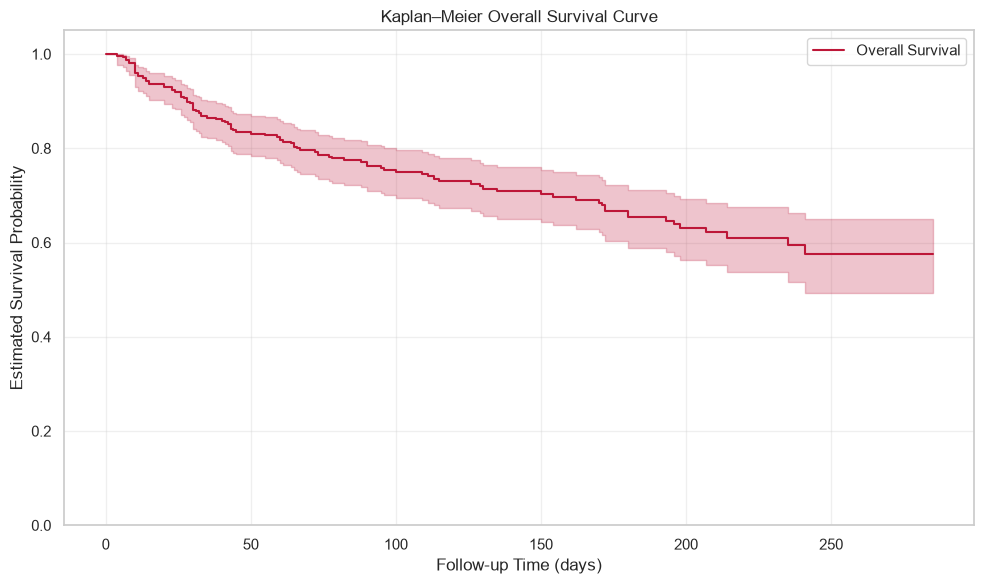

Median survival time: inf


In [3]:

kmf = KaplanMeierFitter()

kmf.fit(
    durations=survival_df["duration"],
    event_observed=survival_df["event"],
    label="Overall Survival"
)

plt.figure(figsize=(10, 6))

kmf.plot_survival_function(
    ci_show=True,
    color="#BD1738"
)

plt.title("Kaplan–Meier Overall Survival Curve")
plt.xlabel("Follow-up Time (days)")
plt.ylabel("Estimated Survival Probability")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Median survival time:", kmf.median_survival_time_)


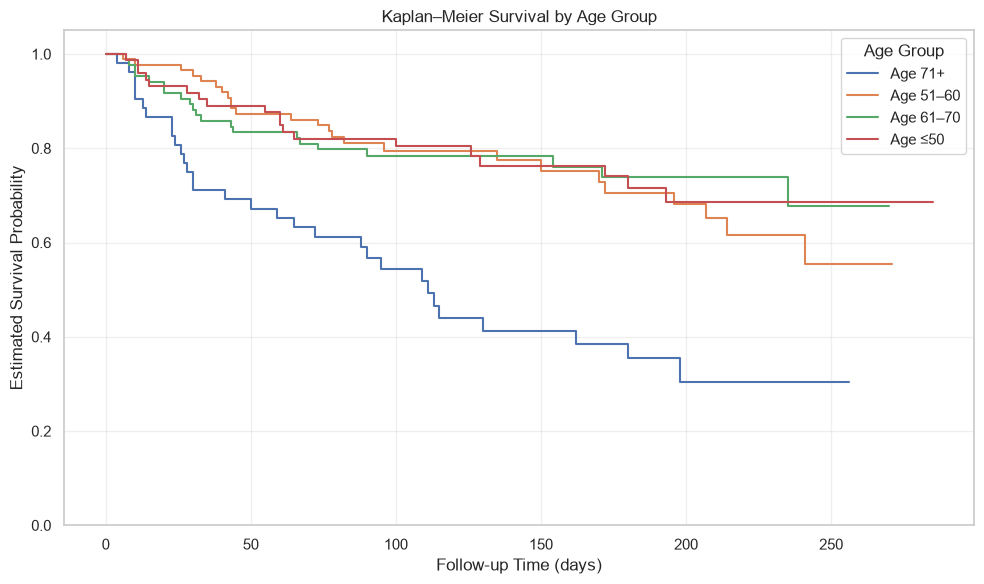

In [4]:

df["Age_Group"] = pd.cut(
    df["age"],
    bins=[0, 50, 60, 70, float("inf")],
    labels=["≤50", "51–60", "61–70", "71+"],
    include_lowest=True
)

plt.figure(figsize=(10, 6))

for group in df["Age_Group"].dropna().unique():
    group_df = df[df["Age_Group"] == group]

    kmf = KaplanMeierFitter()
    kmf.fit(
        durations=group_df["time"],
        event_observed=group_df["DEATH_EVENT"],
        label=f"Age {group}"
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Kaplan–Meier Survival by Age Group")
plt.xlabel("Follow-up Time (days)")
plt.ylabel("Estimated Survival Probability")
plt.ylim(0, 1.05)
plt.legend(title="Age Group")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


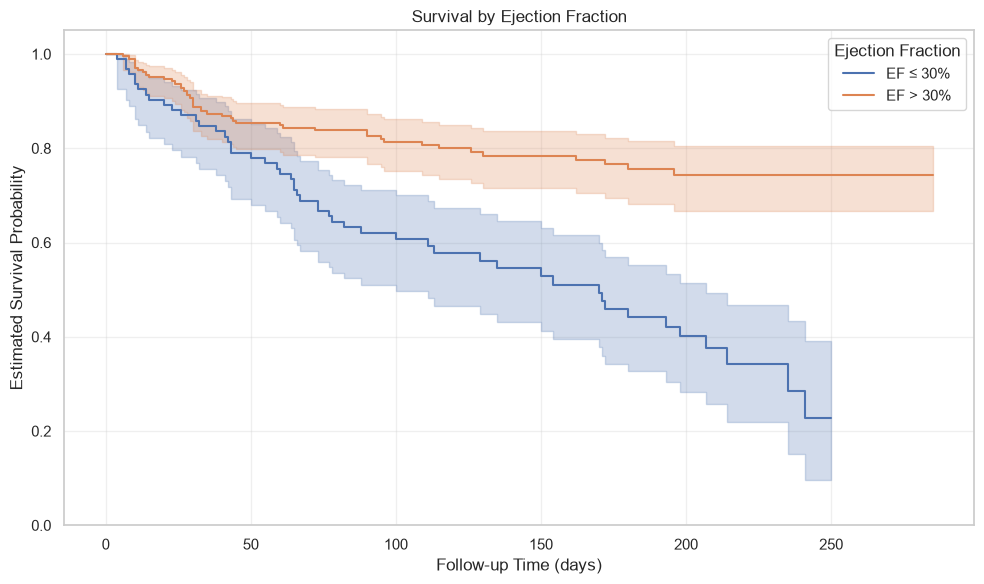

In [5]:

df["EF_Group"] = np.where(
    df["ejection_fraction"] <= 30,
    "EF ≤ 30%",
    "EF > 30%"
)

plt.figure(figsize=(10, 6))

for group in ["EF ≤ 30%", "EF > 30%"]:
    group_df = df[df["EF_Group"] == group]

    kmf = KaplanMeierFitter()
    kmf.fit(
        durations=group_df["time"],
        event_observed=group_df["DEATH_EVENT"],
        label=group
    )
    kmf.plot_survival_function(ci_show=True)

plt.title("Survival by Ejection Fraction")
plt.xlabel("Follow-up Time (days)")
plt.ylabel("Estimated Survival Probability")
plt.ylim(0, 1.05)
plt.legend(title="Ejection Fraction")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:

low_ef = df[df["ejection_fraction"] <= 30]
high_ef = df[df["ejection_fraction"] > 30]

result = logrank_test(
    low_ef["time"],
    high_ef["time"],
    event_observed_A=low_ef["DEATH_EVENT"],
    event_observed_B=high_ef["DEATH_EVENT"]
)

print("Log-rank test statistic:", result.test_statistic)
print("P-value:", result.p_value)

if result.p_value < 0.05:
    print("The survival curves differ statistically at the 0.05 level.")
else:
    print("Insufficient evidence of a difference at the 0.05 level.")


Log-rank test statistic: 30.625705807436223
P-value: 3.12920286801511e-08
The survival curves differ statistically at the 0.05 level.


<lifelines.CoxPHFitter: fitted with 299 total observations, 203 right-censored observations>
             duration col = 'time'
                event col = 'DEATH_EVENT'
      baseline estimation = breslow
   number of observations = 299
number of events observed = 96
   partial log-likelihood = -468.23
         time fit was run = 2026-10-06 03:51:08 UTC

---
                          coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                 
age                       0.05      1.05      0.01            0.03            0.06                1.03                1.07
anaemia                   0.46      1.58      0.22            0.04            0.89                1.04                2.42
creatinine_phosphokinase  0.00      1.00      0.00            0.00            0.00                1.00                1.00
diabetes                  0.14      1.15      0.22           -0.30            0.58                0.74                1.78
ejection_fraction        -0.05      0.95      0.01           -0.07           -0.03                0.93                0.97
high_blood_pressure       0.48      1.61      0.22            0.05            0.90                1.05                2.46
platelets                -0.00      1.00      0.00           -0.00            0.00                1.00                1.00
serum_creatinine          0.32      1.38      0.07            0.18            0.46                1.20                1.58
serum_sodium             -0.04      0.96      0.02           -0.09            0.00                0.91                1.00
sex                      -0.24      0.79      0.25           -0.73            0.26                0.48                1.29
smoking                   0.13      1.14      0.25           -0.36            0.62                0.70                1.86

                          cmp to     z      p  -log2(p)
covariate                                              
age                         0.00  4.98 <0.005     20.56
anaemia                     0.00  2.12   0.03      4.89
creatinine_phosphokinase    0.00  2.23   0.03      5.26
diabetes                    0.00  0.63   0.53      0.91
ejection_fraction           0.00 -4.67 <0.005     18.35
high_blood_pressure         0.00  2.20   0.03      5.17
platelets                   0.00 -0.41   0.68      0.56
serum_creatinine            0.00  4.58 <0.005     17.68
serum_sodium                0.00 -1.90   0.06      4.12
sex                         0.00 -0.94   0.35      1.53
smoking                     0.00  0.51   0.61      0.72
---
Concordance = 0.74
Partial AIC = 958.46
log-likelihood ratio test = 81.95 on 11 df
-log2(p) of ll-ratio test = 40.56

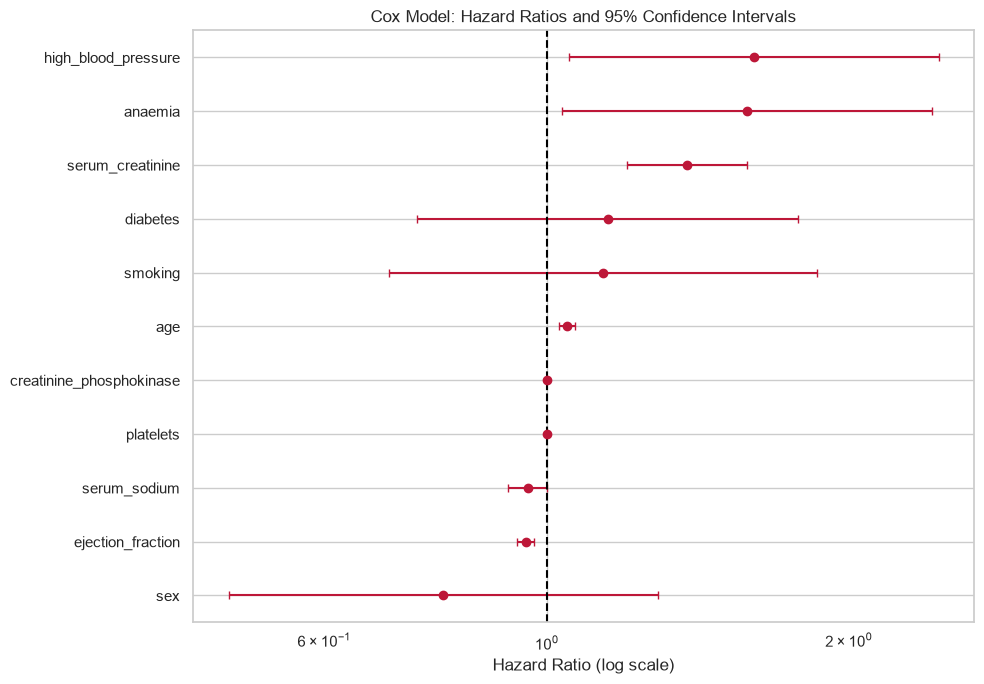

,covariate,HR,Lower CI,Upper CI,p
9,sex,0.788580,0.481588,1.291266,3.451639e-01
4,ejection_fraction,0.952237,0.932885,0.971990,2.984594e-06
8,serum_sodium,0.956775,0.914126,1.001413,5.753090e-02
6,platelets,1.000000,0.999997,1.000002,6.806373e-01
2,creatinine_phosphokinase,1.000221,1.000026,1.000415,2.604761e-02
0,age,1.047502,1.028533,1.066821,6.448780e-07
10,smoking,1.137602,0.695262,1.861368,6.078267e-01
3,diabetes,1.150141,0.742690,1.781124,5.307444e-01
7,serum_creatinine,1.378552,1.201419,1.581801,4.759997e-06
1,anaemia,1.584288,1.035768,2.423292,3.383470e-02


In [9]:

cox_df = df.drop(columns=["Age_Group", "EF_Group"]).copy()

cph = CoxPHFitter()
cph.fit(cox_df, duration_col="time", event_col="DEATH_EVENT")
cph.print_summary()

summary = cph.summary.reset_index()

# Hazard ratios and confidence intervals
summary["HR"] = np.exp(summary["coef"])
summary["Lower CI"] = np.exp(summary["coef lower 95%"])
summary["Upper CI"] = np.exp(summary["coef upper 95%"])

summary = summary.sort_values("HR")

plt.figure(figsize=(10, 7))

y = np.arange(len(summary))
plt.errorbar(
    summary["HR"],
    y,
    xerr=[
        summary["HR"] - summary["Lower CI"],
        summary["Upper CI"] - summary["HR"]
    ],
    fmt="o",
    capsize=3,
    color="#BD1738"
)

plt.axvline(1, color="black", linestyle="--")
plt.yticks(y, summary["covariate"])
plt.xscale("log")
plt.xlabel("Hazard Ratio (log scale)")
plt.title("Cox Model: Hazard Ratios and 95% Confidence Intervals")
plt.tight_layout()
plt.show()

display(summary[
    ["covariate", "HR", "Lower CI", "Upper CI", "p"]
])


In [10]:

low_ef = df[df["ejection_fraction"] <= 30]
high_ef = df[df["ejection_fraction"] > 30]

result = logrank_test(
    low_ef["time"],
    high_ef["time"],
    event_observed_A=low_ef["DEATH_EVENT"],
    event_observed_B=high_ef["DEATH_EVENT"]
)

print("Log-rank test statistic:", result.test_statistic)
print("P-value:", result.p_value)

if result.p_value < 0.05:
    print("The survival curves differ statistically at the 0.05 level.")
else:
    print("Insufficient evidence of a difference at the 0.05 level.")


Log-rank test statistic: 30.625705807436223
P-value: 3.12920286801511e-08
The survival curves differ statistically at the 0.05 level.



   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'ejection_fraction' failed the non-proportional test: p-value is 0.0127.

   Advice 1: the functional form of the variable 'ejection_fraction' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'ejection_fraction' using pd.cut, and then specify it in
`strata=['ejection_fraction', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment

[[<Axes: xlabel='rank-transformed time\n(p=0.8631)'>,
  <Axes: xlabel='km-transformed time\n(p=0.7427)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.9281)'>,
  <Axes: xlabel='km-transformed time\n(p=0.9988)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.2928)'>,
  <Axes: xlabel='km-transformed time\n(p=0.2882)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.9884)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8382)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0127)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0156)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.7390)'>,
  <Axes: xlabel='km-transformed time\n(p=0.7393)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.7359)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8493)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0623)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0727)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1881)'>,
  <Axes: xlabel='km-transformed time\n(p=0.2950)'>],
 [<Axes: xlabel='rank-transformed tim

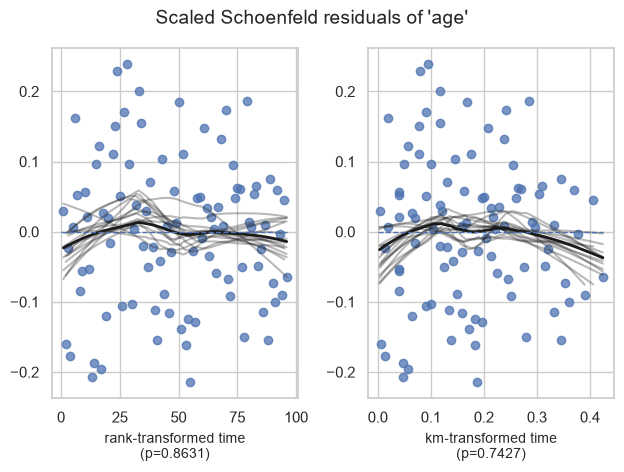

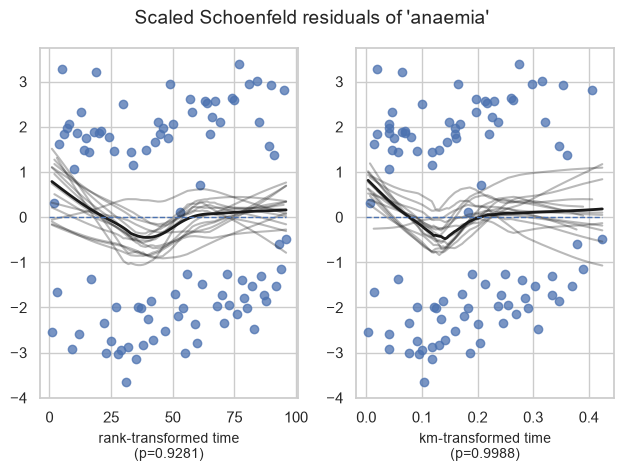

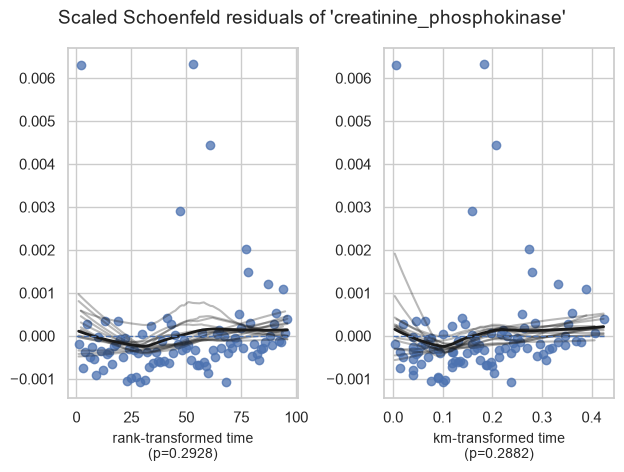

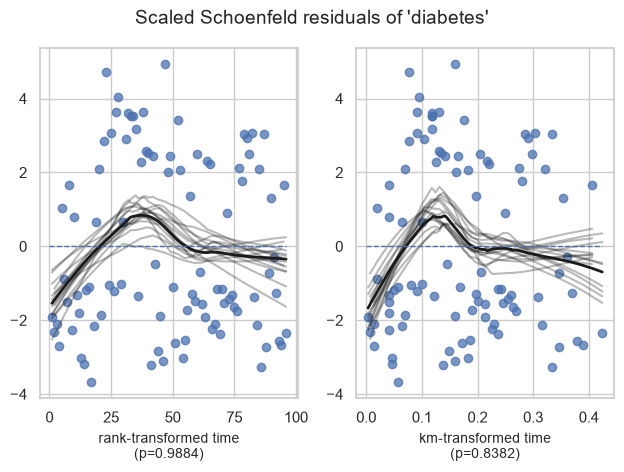

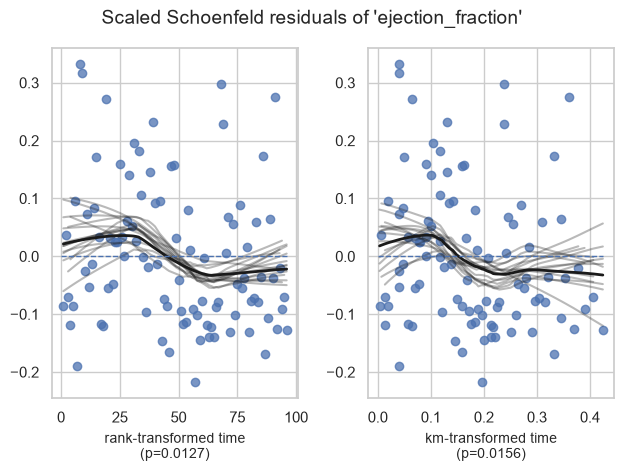

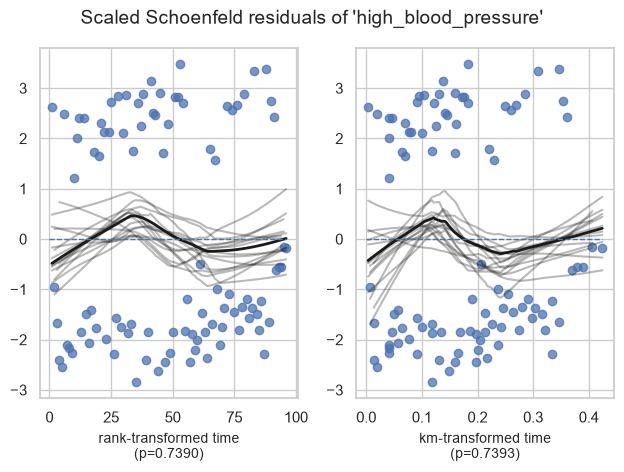

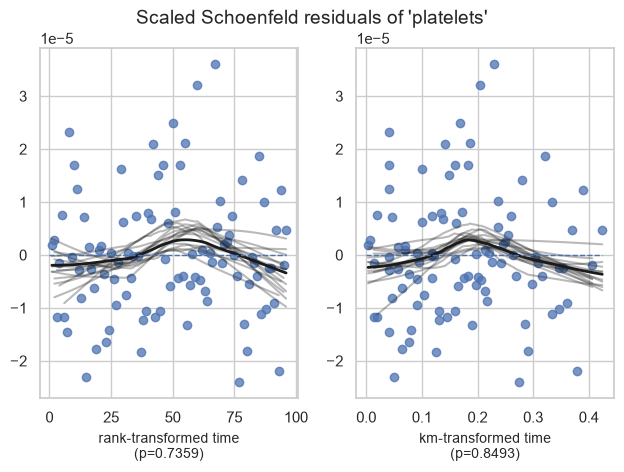

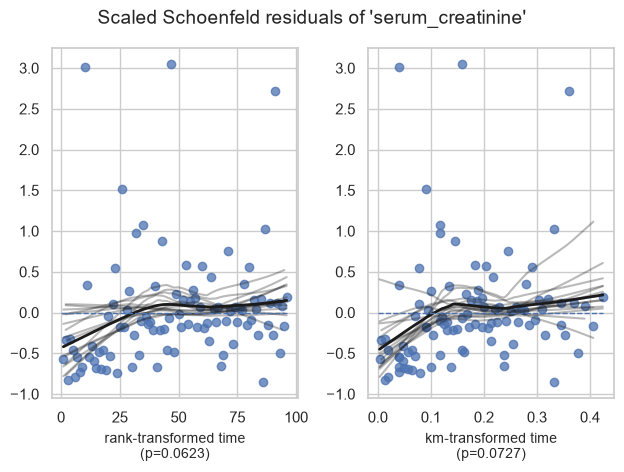

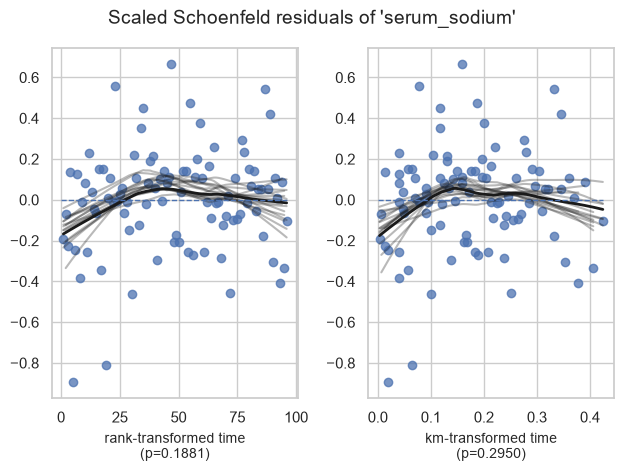

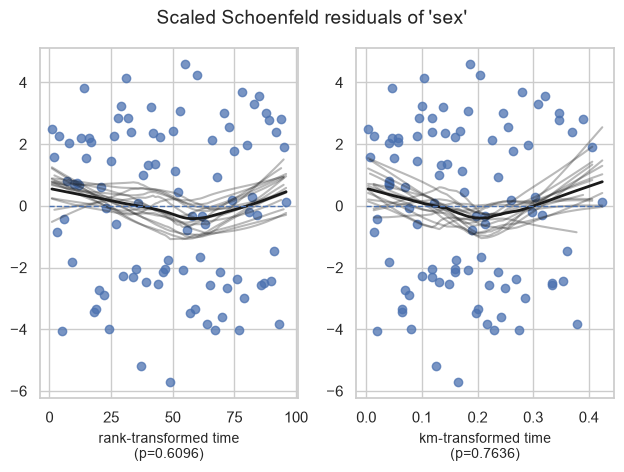

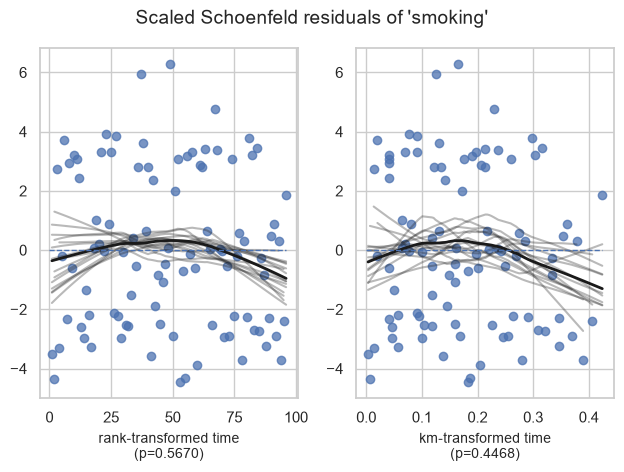

In [12]:

# This is a diagnostic test of the Cox model assumption.
# It may flag variables because of small sample size or model complexity.
cph.check_assumptions(
    df,
    p_value_threshold=0.05,
    show_plots=True
)


In [10]:

OUTPUT_DIR = PROJECT_DIR / "visualizations"
OUTPUT_DIR.mkdir(exist_ok=True)

# Save overall Kaplan-Meier curve
kmf = KaplanMeierFitter()
kmf.fit(
    df["time"],
    event_observed=df["DEATH_EVENT"],
    label="Overall Survival"
)

ax = kmf.plot_survival_function(ci_show=True)
ax.set_title("Kaplan–Meier Overall Survival")
ax.set_xlabel("Follow-up Time (days)")
ax.set_ylabel("Survival Probability")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "kaplan_meier_overall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# Export Cox summary
cph.summary.to_csv(
    OUTPUT_DIR / "cox_model_summary.csv"
)

print("Survival analysis completed.")
print("Results saved to:", OUTPUT_DIR)


Survival analysis completed.
Results saved to: c:\Users\vaibh\OneDrive\Desktop\Heart_Failure_Survival_Analysis\visualizations
